##**EDAB2724 Assignment 2 Group 2**









##Name and Student Number:

*  Thembani Prince Mncube 2022119990
*  Luyanda Shezi          2023938158
*  Kutlwano Mofokeng      2025039310
*  Edwin Van Zyl          2024103554
*  Talha Dindar           2026760856
*  Ofentse Ngcongca       2025513058
*  Ismael Dlamini         2023643998

Setup and Fix Random Seed for Reproducibility.

In [ ]:
# 1. CORE + REPRODUCIBILITY
import pandas as pd
import numpy as np
import random
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

Load datasets.

In [ ]:
#load the dataset from local device
from google.colab import files
uploaded = files.upload()

Define dataset.

In [ ]:
train = pd.read_csv('training.csv')
oos = pd.read_csv('OOS test.csv')
oot = pd.read_csv('OOT test.csv')

Check quality of dataset.

In [ ]:
# DATA QUALITY CHECK
print("=== DATA QUALITY AUDIT ===\n")

# check train, oos, oot one by one
datasets = [train, oos, oot]
names = ['TRAIN', 'OOS', 'OOT']

for i in range(len(datasets)):
    df = datasets[i]
    name = names[i]

    print("--- " + name + " ---")
    print("Shape:", df.shape)

    # missing values
    total_missing = df.isnull().sum().sum()
    print("Total missing:", total_missing)

    cols_with_missing = df.isnull().sum()
    cols_with_missing = cols_with_missing[cols_with_missing > 0]
    if len(cols_with_missing) > 0:
        print("Missing per column:")
        print(cols_with_missing)
    else:
        print("Missing per column: 0")

    # check duplicates on Loanref
    dups = df.duplicated(subset=['Loanref']).sum()
    print("Duplicated Loanref:", dups)

    # check target
    print("DFlag values:", df['DFlag'].unique())

    # check ranges
    print("Credit_Score range:", df['Credit_Score'].min(), "to", df['Credit_Score'].max())
    print("DTI > 100 count:", (df['Debt_to_income'] > 100).sum())
    print("")# DATA QUALITY CHECK

=== DATA QUALITY AUDIT ===

--- TRAIN ---
Shape: (231064, 80)
Total missing: 16
Missing per column:
CLoan_to_value     3
Debt_to_income    10
OLoan_to_value     3
dtype: int64
Duplicated Loanref: 0
DFlag values: [0 1]
Credit_Score range: 599 to 729
DTI > 100 count: 0

--- OOS ---
Shape: (232515, 80)
Total missing: 17
Missing per column:
CLoan_to_value     3
Debt_to_income    11
OLoan_to_value     3
dtype: int64
Duplicated Loanref: 0
DFlag values: [0 1]
Credit_Score range: 518 to 729
DTI > 100 count: 0

--- OOT ---
Shape: (352788, 80)
Total missing: 42
Missing per column:
Mortgage_Insurance     2
CLoan_to_value        10
Debt_to_income        20
OLoan_to_value        10
dtype: int64
Duplicated Loanref: 0
DFlag values: [0 1]
Credit_Score range: 600 to 729
DTI > 100 count: 0



Missing Value Imputation.

In [ ]:
# IMPUTATION

# only these 4 have missing, the 72 dummies are fine
cols_to_impute = ['Credit_Score','Debt_to_income','CLoan_to_value','OLoan_to_value']
print("Columns to impute:", cols_to_impute)

# use median because DTI and LTV have outliers, mean would be too high
from sklearn.impute import SimpleImputer
imp = SimpleImputer(strategy='median')

# important: learn median from train only, then apply to others
# this is to avoid data leakage
train[cols_to_impute] = imp.fit_transform(train[cols_to_impute])
oos[cols_to_impute] = imp.transform(oos[cols_to_impute])
oot[cols_to_impute] = imp.transform(oot[cols_to_impute])

print("After imputation missing in train:", train.isnull().sum().sum())
print("Medians from TRAIN:")
for j in range(len(cols_to_impute)):
    print(cols_to_impute[j], ":", imp.statistics_[j])

Columns to impute: ['Credit_Score', 'Debt_to_income', 'CLoan_to_value', 'OLoan_to_value']
After imputation missing in train: 0
Medians from TRAIN:
Credit_Score : 701.0
Debt_to_income : 37.0
CLoan_to_value : 80.0
OLoan_to_value : 79.0


Dimensions.

In [ ]:
# 2. Dimensions
print("=== DIMENSIONS ===")

# train shape
print("train shape:", train.shape)
print("train has", train.shape[0], "loans and", train.shape[1], "columns")

# oos and oot shape
print("oos shape:", oos.shape)
print("oot shape:", oot.shape)

=== DIMENSIONS ===
train shape: (231064, 80)
train has 231064 loans and 80 columns
oos shape: (232515, 80)
oot shape: (352788, 80)


Data types.

In [ ]:
# 3. Data types
print("\n=== DATA TYPES ===")

# count how many int, float etc
print(train.dtypes.value_counts())

# check first 10 cols
print("\nFirst 10 cols:")
print(train.dtypes.head(10))

# check last 10 cols
print("\nLast 10 cols:")
print(train.dtypes.tail(10))


=== DATA TYPES ===
int64      75
float64     4
object      1
Name: count, dtype: int64

First 10 cols:
Loanref                  object
Credit_Score            float64
Mortgage_Insurance        int64
Number_of_units           int64
CLoan_to_value          float64
Debt_to_income          float64
OLoan_to_value          float64
Single_borrower           int64
is_Loan_purpose_purc      int64
is_Loan_purpose_cash      int64
dtype: object

Last 10 cols:
is_property_state_TX    int64
is_property_state_UT    int64
is_property_state_VA    int64
is_property_state_VI    int64
is_property_state_VT    int64
is_property_state_WA    int64
is_property_state_WI    int64
is_property_state_WV    int64
is_property_state_WY    int64
DFlag                   int64
dtype: object


Target Variable Distribution Check.

In [ ]:
# 4. Target values
print("\n=== TARGET DFlag ===")

# check TRAIN
print("TRAIN:", train['DFlag'].value_counts().to_dict())
print("TRAIN default rate:", train['DFlag'].mean()*100, "%")
print("TRAIN unique:", train['DFlag'].unique())

# check OOS
print("\nOOS:", oos['DFlag'].value_counts().to_dict())
print("OOS default rate:", oos['DFlag'].mean()*100, "%")
print("OOS unique:", oos['DFlag'].unique())

# check OOT
print("\nOOT:", oot['DFlag'].value_counts().to_dict())
print("OOT default rate:", oot['DFlag'].mean()*100, "%")
print("OOT unique:", oot['DFlag'].unique())



=== TARGET DFlag ===
TRAIN: {0: 230473, 1: 591}
TRAIN default rate: 0.2557732922480352 %
TRAIN unique: [0 1]

OOS: {0: 231919, 1: 596}
OOS default rate: 0.25632754876029507 %
OOS unique: [0 1]

OOT: {0: 351862, 1: 926}
OOT default rate: 0.26248058323979273 %
OOT unique: [0 1]



**Report:**
Target is binary {0,1} validSevere imbalance ∼0.256%Same rate across TRAIN/OOS/OOT so comparison is fair.

Purpose of each file.

In [ ]:
# 5. Purpose of each file
print("\n=== PURPOSE ===")

print("TRAIN: data from 2010-2016, this is where we train the model")
print("OOS: also 2010-2016 but different loans, used to test if model generalizes")
print("OOT: data from 2017, used to test if model still works over time")


=== PURPOSE ===
TRAIN: data from 2010-2016, this is where we train the model
OOS: also 2010-2016 but different loans, used to test if model generalizes
OOT: data from 2017, used to test if model still works over time


Predictor columns alignment check.

In [ ]:
# 6. Predictor columns aligned?
print("\n=== ALIGNMENT CHECK ===")

# check if columns are same order
same_cols = (train.columns == oos.columns).all() and (train.columns == oot.columns).all()
print("All files have same columns in same order?", same_cols)

# show some columns
print("First 4 columns:", train.columns.tolist()[:4])
print("Last predictor:", train.columns.tolist()[-2])

print("\nTotal = 7 original + 72 dummies + DFlag = 80")
print("7 original:", train.columns[:7].tolist())
print("72 dummies count:", len(train.columns[7:-1]))


=== ALIGNMENT CHECK ===
All files have same columns in same order? True
First 4 columns: ['Loanref', 'Credit_Score', 'Mortgage_Insurance', 'Number_of_units']
Last predictor: is_property_state_WY

Total = 7 original + 72 dummies + DFlag = 80
7 original: ['Loanref', 'Credit_Score', 'Mortgage_Insurance', 'Number_of_units', 'CLoan_to_value', 'Debt_to_income', 'OLoan_to_value']
72 dummies count: 72


**Report**-"Predictor columns aligned = True across TRAIN/OOS/OOT in both name and order, confirmed by (train.columns == oos.columns).all(). Total 80 columns = 7 original + 72 dummies + DFlag target, so X_train, X_oos, X_oot can be fed directly into same model without re-encoding."

In [ ]:
print("=== DATA QUALITY AUDIT ===\n")

# TRAIN
print("--- TRAIN ---")
print("Dimensions:", train.shape)
print("Total missing:", train.isnull().sum().sum())
missing = train.isnull().sum()
missing = missing[missing > 0]
print("Missing per column:", "None" if missing.empty else f"\n{missing}")
print("Duplicated Loanref:", train.duplicated(subset=['Loanref']).sum())
print("DFlag unique:", train['DFlag'].unique())
print("Credit_Score range:", train['Credit_Score'].min(), "-", train['Credit_Score'].max())
print("DTI >100 count:", (train['Debt_to_income']>100).sum())
print("")

# OOS
print("--- OOS ---")
print("Dimensions:", oos.shape)
print("Total missing:", oos.isnull().sum().sum())
missing = oos.isnull().sum()
missing = missing[missing > 0]
print("Missing per column:", "None" if missing.empty else f"\n{missing}")
print("Duplicated Loanref:", oos.duplicated(subset=['Loanref']).sum())
print("DFlag unique:", oos['DFlag'].unique())
print("Credit_Score range:", oos['Credit_Score'].min(), "-", oos['Credit_Score'].max())
print("DTI >100 count:", (oos['Debt_to_income']>100).sum())
print("")

# OOT
print("--- OOT ---")
print("Dimensions:", oot.shape)
print("Total missing:", oot.isnull().sum().sum())
missing = oot.isnull().sum()
missing = missing[missing > 0]
print("Missing per column:", "None" if missing.empty else f"\n{missing}")
print("Duplicated Loanref:", oot.duplicated(subset=['Loanref']).sum())
print("DFlag unique:", oot['DFlag'].unique())
print("Credit_Score range:", oot['Credit_Score'].min(), "-", oot['Credit_Score'].max())
print("DTI >100 count:", (oot['Debt_to_income']>100).sum())

=== DATA QUALITY AUDIT ===

--- TRAIN ---
Dimensions: (231064, 80)
Total missing: 0
Missing per column: None
Duplicated Loanref: 0
DFlag unique: [0 1]
Credit_Score range: 599.0 - 729.0
DTI >100 count: 0

--- OOS ---
Dimensions: (232515, 80)
Total missing: 0
Missing per column: None
Duplicated Loanref: 0
DFlag unique: [0 1]
Credit_Score range: 518.0 - 729.0
DTI >100 count: 0

--- OOT ---
Dimensions: (352788, 80)
Total missing: 2
Missing per column: 
Mortgage_Insurance    2
dtype: int64
Duplicated Loanref: 0
DFlag unique: [0 1]
Credit_Score range: 600.0 - 729.0
DTI >100 count: 0


 Cleaning decision

In [ ]:
# DECISION 1: Handling columns with missing values.
num_cols = ['Credit_Score','Debt_to_income','CLoan_to_value','OLoan_to_value']
print("Columns to impute:", num_cols)
print("72 dummy columns have no missing")

# DECISION 2: Using the median
# DTI and LTV have outliers so mean will be too high, median is better
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')

# DECISION 3: Fit only on train to avoid leakage i.e Learn from the past only, not the future.
train[num_cols] = imputer.fit_transform(train[num_cols])
oos[num_cols] = imputer.transform(oos[num_cols])
oot[num_cols] = imputer.transform(oot[num_cols])

print("\nAfter imputation missing in train:", train.isnull().sum().sum())
print("Medians from TRAIN only:")
for i in range(len(num_cols)):
    print(num_cols[i], ":", imputer.statistics_[i])

# DECISION 4: Handling Duplicates.
# Loanref should be unique, result is 0 so no need to drop
# if duplicates found we would do df.drop_duplicates(subset=['Loanref'])

# DECISION 5: Handling Outliers.
# kept them, because in credit risk outliers are real high risk customers.
# also XGBoost can handle outliers well so no removal needed

Columns to impute: ['Credit_Score', 'Debt_to_income', 'CLoan_to_value', 'OLoan_to_value']
72 dummy columns have no missing

After imputation missing in train: 0
Medians from TRAIN only:
Credit_Score : 701.0
Debt_to_income : 37.0
CLoan_to_value : 80.0
OLoan_to_value : 79.0


In [ ]:
print("=== CLASS IMBALANCE AUDIT ===\n")

# TRAIN
total = len(train)
defaults = train['DFlag'].sum()
non_defaults = total - defaults
print("TRAIN:")
print("  Total:", total)
print("  Non-default (0):", non_defaults)
print("  Default (1):", defaults)
print("  % Default:", defaults/total*100, "%")
print("  Ratio:", non_defaults/defaults, ":1")
print("")

# OOS
total = len(oos)
defaults = oos['DFlag'].sum()
non_defaults = total - defaults
print("OOS:")
print("  Total:", total)
print("  Non-default (0):", non_defaults)
print("  Default (1):", defaults)
print("  % Default:", defaults/total*100, "%")
print("  Ratio:", non_defaults/defaults, ":1")
print("")

# OOT
total = len(oot)
defaults = oot['DFlag'].sum()
non_defaults = total - defaults
print("OOT:")
print("  Total:", total)
print("  Non-default (0):", non_defaults)
print("  Default (1):", defaults)
print("  % Default:", defaults/total*100, "%")
print("  Ratio:", non_defaults/defaults, ":1")
print("")

# table for report
import pandas as pd

data = []
for df, name in [(train,'TRAIN'), (oos,'OOS'), (oot,'OOT')]:
    total = len(df)
    d = df['DFlag'].sum()
    nd = total - d
    data.append([name, total, nd, d, str(round(d/total*100,3))+"%", str(round(nd/d)) + ":1"])

summary_df = pd.DataFrame(data, columns=['File','Total','Non-Default','Default','% Default','Ratio'])
print(summary_df)

=== CLASS IMBALANCE AUDIT ===

TRAIN:
  Total: 231064
  Non-default (0): 230473
  Default (1): 591
  % Default: 0.2557732922480352 %
  Ratio: 389.97123519458546 :1

OOS:
  Total: 232515
  Non-default (0): 231919
  Default (1): 596
  % Default: 0.25632754876029507 %
  Ratio: 389.1258389261745 :1

OOT:
  Total: 352788
  Non-default (0): 351862
  Default (1): 926
  % Default: 0.26248058323979273 %
  Ratio: 379.9805615550756 :1

    File   Total  Non-Default  Default % Default  Ratio
0  TRAIN  231064       230473      591    0.256%  390:1
1    OOS  232515       231919      596    0.256%  389:1
2    OOT  352788       351862      926    0.262%  380:1


**Modelling Problem**
With extreme class imbalance (~0.26% defaults, or ~390:1 ratio), standard machine learning algorithms will naturally bias their decision boundaries toward the majority non-default class to minimize overall loss. Consequently, the model will struggle to learn the subtle risk patterns of defaulters and may simply predict "non-default" for every loan, rendering it practically useless for credit risk management.

**Evaluation Problem**
Standard evaluation metrics like overall accuracy become completely misleading because a naive model predicting 0 for every single observation would achieve a deceptive ~99.74% accuracy while failing to catch a single actual default. Therefore, threshold-agnostic and minority-focused metrics like Precision-Recall AUC (AUPR) and cost-sensitive trade-offs must be used instead of standard accuracy or ROC-AUC to evaluate true risk performance.

**10 Key Variables for Mortgage Default Risk**

**Credit_Score:** Shows how good the borrower was with credit before. If the score is low it means they had problems paying in the past and are more likely to default later.

**Debt_to_income (DTI):** This is how much of the borrower's monthly income goes to paying debts. If DTI is high, they are already using most of their income for debt so any extra cost can cause them to miss payments.

**CLoan_to_value (CLTV):** This is the current loan amount including any second loans compared to the house value. When this ratio is high there is not much equity left, so if house prices fall the borrower is in a riskier position.

**OLoan_to_value (OLTV):** This is the original loan amount compared to the house value at the start. A high value means the borrower made a small down payment and has less of their own money in the property.

**Mortgage_Insurance:** Shows if the loan needs insurance, which usually happens when LTV is over 80%. This flags loans where the borrower put down very little money so they are seen as more risky.

**Single_borrower:** Shows if there is only one borrower on the loan instead of two. If one person loses their job or has an emergency there is no second income to cover it, so the risk of default is higher.

**is_Loan_purpose_cash:** This is for cash-out refinance where the borrower takes money out of their house equity. These loans usually default more because the total debt goes up.

**is_Loan_purpose_purc:** Shows the loan is for buying a house. These usually have less risk than cash-out refi( which is refinance) because the buyer puts their own money in.

**Number_of_units:** How many units are in the property. More units means more risk because the owner has to deal with renters and if units stay empty they lose income.

**is_property_state_NV / FL / CA:** Shows what state the property is in. Some states have more unstable housing markets, so if jobs drop or prices fall there, defaults can spike in that area.



#Part B - Exploratory Data Analysis

##1. Visualising the default/non-default distribution

In [ ]:

values =train["DFlag"].value_counts()
print("DFlag values:")
print(values)
percentage = train["DFlag"].value_counts(normalize=True)*100
print("DFlag percentages:")
print(percentage)


DFlag values:
DFlag
0    230473
1       591
Name: count, dtype: int64
DFlag percentages:
DFlag
0    99.744227
1     0.255773
Name: proportion, dtype: float64


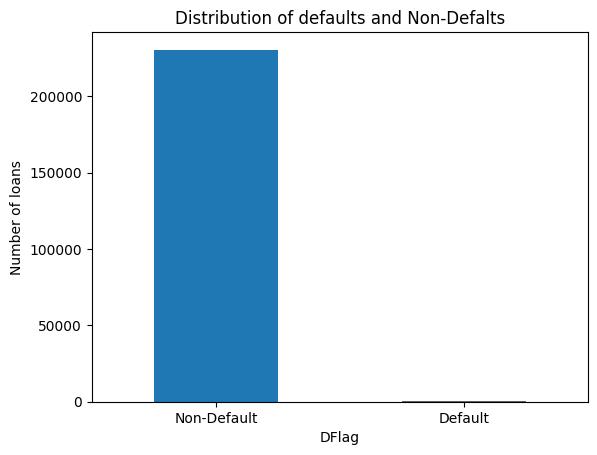

In [ ]:
import matplotlib.pyplot as plt
train["DFlag"].value_counts().plot(kind='bar')
plt.title("Distribution of defaults and Non-Defalts")
plt.xlabel("DFlag")
plt.ylabel("Number of loans")
plt.xticks([0, 1], ["Non-Default", "Default"], rotation=0)
plt.show()

#Graph interpretation
The graph show an imbalanced distribution between the defaults and non-defaults for the DFlag variable. 99.744227% of loans did not default and 0.256% of loans are default. A model built to detect non-defaults could conclude, with very high accuracy, that almost all loans are non-default. The defaults could be missed or ignored.

##2. Relationship between  default and the main numerical risk variables

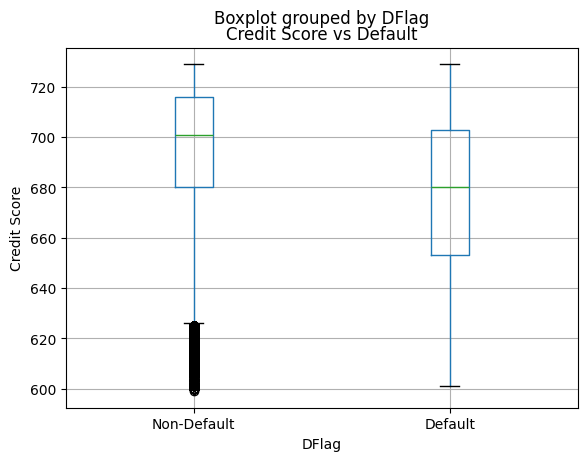

In [ ]:
train.boxplot(
    column=["Credit_Score"],
    by="DFlag"
)
plt.title("Credit Score vs Default")
plt.xlabel("DFlag")
plt.ylabel("Credit Score")
plt.xticks([1, 2], ["Non-Default", "Default"], rotation=0)
plt.show()


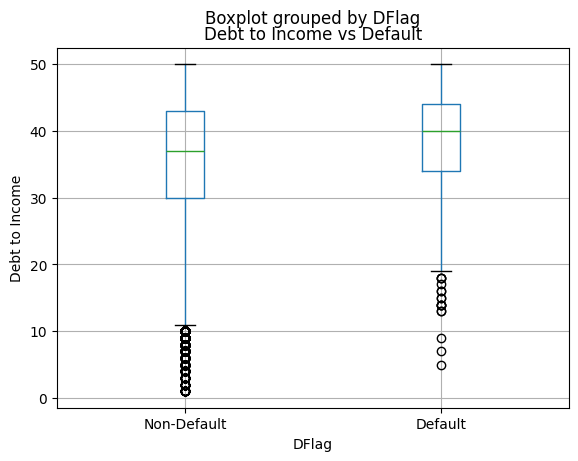

In [ ]:
train.boxplot(
    column=[ "Debt_to_income"],
    by="DFlag"
)
plt.title("Debt to Income vs Default")
plt.xlabel("DFlag")
plt.ylabel("Debt to Income")
plt.xticks([1, 2],["Non-Default", "Default"], rotation=0)
plt.show()

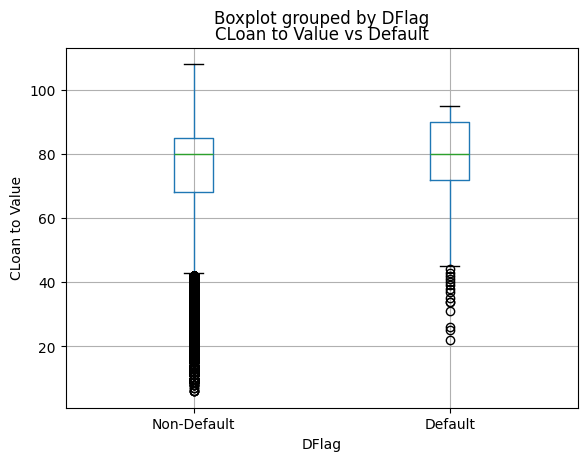

In [ ]:
train.boxplot(
    column=[ "CLoan_to_value"],
    by="DFlag"
)

plt.title("CLoan to Value vs Default")
plt.xlabel("DFlag")
plt.ylabel("CLoan to Value")
plt.xticks([1, 2], ["Non-Default", "Default"], rotation=0)
plt.show()

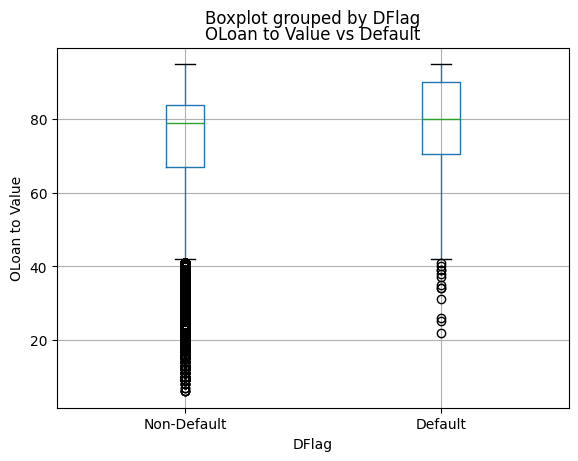

In [ ]:
train.boxplot(
    column=[ "OLoan_to_value"],
    by="DFlag"
)
plt.title("OLoan to Value vs Default")
plt.xlabel("DFlag")
plt.ylabel("OLoan to Value")
plt.xticks([1, 2], ["Non-Default", "Default"], rotation=0)
plt.show()

##3. Default rates for Loan Purpose, Occupancy Status,First Time Homeowner Status

In [ ]:
drate1 = train.groupby("is_Loan_purpose_purc")["DFlag"].mean() *100
drate2 = train.groupby("is_Loan_purpose_cash")["DFlag"].mean() *100
drate3 = train.groupby("is_Loan_purpose_noca")["DFlag"].mean() *100

print("The default rate for ",drate1)
print("The default rate for ",drate2)
print("The default rate for ",drate3)



The default rate for  is_Loan_purpose_purc
0    0.204233
1    0.321785
Name: DFlag, dtype: float64
The default rate for  is_Loan_purpose_cash
0    0.260407
1    0.244628
Name: DFlag, dtype: float64
The default rate for  is_Loan_purpose_noca
0    0.290835
1    0.159946
Name: DFlag, dtype: float64


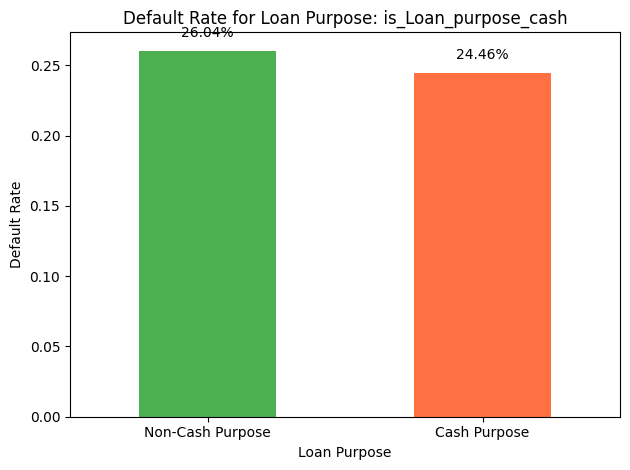

In [ ]:
import matplotlib.pyplot as plt

# Assuming drate2 is a Series with index [0, 1] and values = default rate

ax = drate2.plot(kind="bar", color=['#4CAF50', '#FF7043'])

plt.title("Default Rate for Loan Purpose: is_Loan_purpose_cash")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate")
plt.xticks([0, 1], ["Non-Cash Purpose", "Cash Purpose"], rotation=0)

# add values on top of bars
for i, v in enumerate(drate2):
    ax.text(i, v + 0.01, f"{v:.2%}", ha='center')

plt.tight_layout()
plt.show()

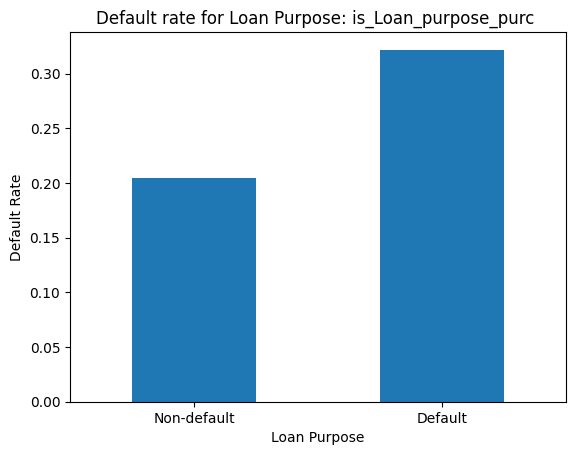

In [ ]:
#graph for is Loan Purchace Purchase
drate1.plot(kind= "bar")
plt.title("Default rate for Loan Purpose: is_Loan_purpose_purc ")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate")
plt.xticks([0,1], ["Non-default", "Default"], rotation=0)
plt.show()

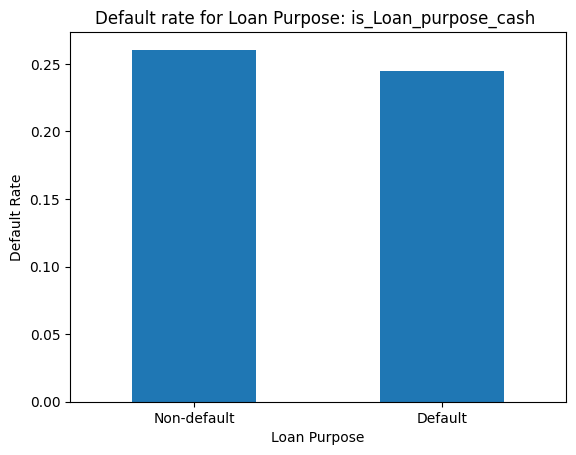

In [ ]:
#Graph for is_Loan_purpose_cash
drate2.plot(kind= "bar")
plt.title("Default rate for Loan Purpose: is_Loan_purpose_cash ")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate")
plt.xticks([0,1], ["Non-default", "Default"], rotation=0)
plt.show()

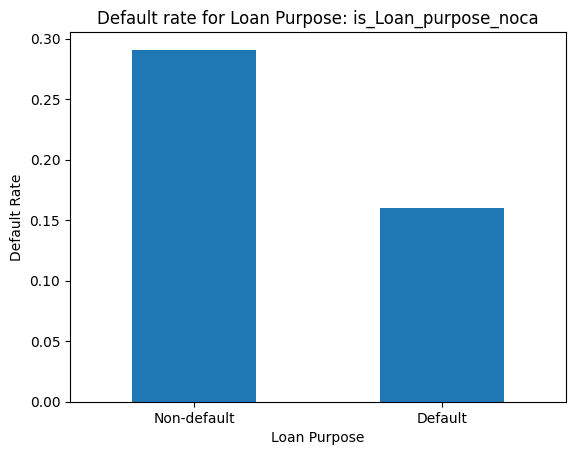

In [ ]:
#graph for is loan purpose No cash
drate3.plot(kind= "bar")
plt.title("Default rate for Loan Purpose: is_Loan_purpose_noca")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate")
plt.xticks([0,1], ["Non-default", "Default"], rotation=0)
plt.show()

##4. Comparing the distribution

In [ ]:
t =train.columns.tolist()
os = oos.columns.tolist()
ot =oot.columns.tolist()
print(t)
print(os)
print(ot)

['Loanref', 'Credit_Score', 'Mortgage_Insurance', 'Number_of_units', 'CLoan_to_value', 'Debt_to_income', 'OLoan_to_value', 'Single_borrower', 'is_Loan_purpose_purc', 'is_Loan_purpose_cash', 'is_Loan_purpose_noca', 'is_First_time_homeowner', 'is_First_time_homeowner_No', 'is_First_time_homeowner_miss', 'is_Occupancy_status_prim', 'is_Occupancy_status_inve', 'is_Occupancy_status_seco', 'is_Origination_channel_reta', 'is_Origination_channel_brok', 'is_Origination_channel_corr', 'is_Property_type_cond', 'is_Property_type_coop', 'is_Property_type_manu', 'is_Property_type_pud', 'is_Property_type_sing', 'is_property_state_AK', 'is_property_state_AL', 'is_property_state_AR', 'is_property_state_AZ', 'is_property_state_CA', 'is_property_state_CO', 'is_property_state_CT', 'is_property_state_DC', 'is_property_state_DE', 'is_property_state_FL', 'is_property_state_GA', 'is_property_state_GU', 'is_property_state_HI', 'is_property_state_IA', 'is_property_state_ID', 'is_property_state_IL', 'is_property

In [ ]:
#Summary Stats
import seaborn as sns
import pandas as pd

predictors =[
    'Credit_Score',
    'Debt_to_income',
    'CLoan_to_value',
    'OLoan_to_value',
    'Single_borrower',
]

datasets = {'TRAIN': train, 'OOS': oos, 'OOT': oot}

for var in predictors:
  print("\n Summary Statistics: ")
  summary_stats = pd.DataFrame({
      'TRAIN': datasets['TRAIN'][var].describe(),
      'OOS': datasets['OOS'][var].describe(),
      'OOT': datasets['OOT'][var].describe()
  })
  print(summary_stats)


 Summary Statistics: 
               TRAIN            OOS            OOT
count  231064.000000  232515.000000  352788.000000
mean      695.010110     694.965508     692.587903
std        25.762936      25.787806      27.523514
min       599.000000     518.000000     600.000000
25%       680.000000     680.000000     676.000000
50%       701.000000     700.000000     699.000000
75%       716.000000     716.000000     715.000000
max       729.000000     729.000000     729.000000

 Summary Statistics: 
               TRAIN            OOS            OOT
count  231064.000000  232515.000000  352788.000000
mean       35.840023      35.861132      37.101789
std         8.444078       8.434981       8.683568
min         1.000000       1.000000       1.000000
25%        30.000000      30.000000      31.000000
50%        37.000000      37.000000      39.000000
75%        43.000000      43.000000      44.000000
max        50.000000      51.000000      50.000000

 Summary Statistics: 
             

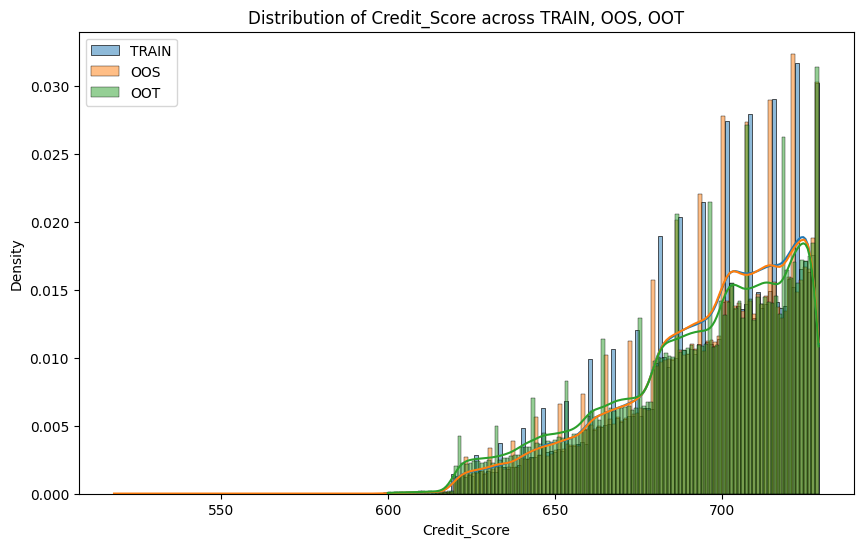

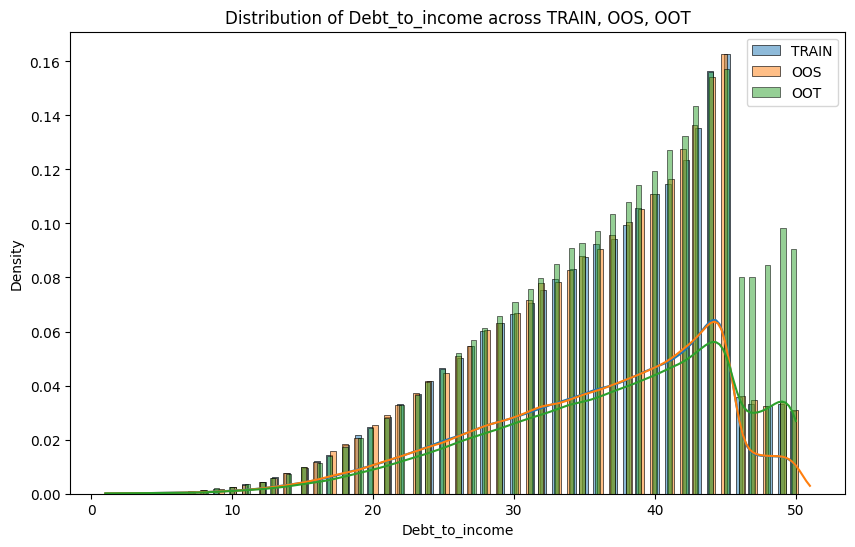

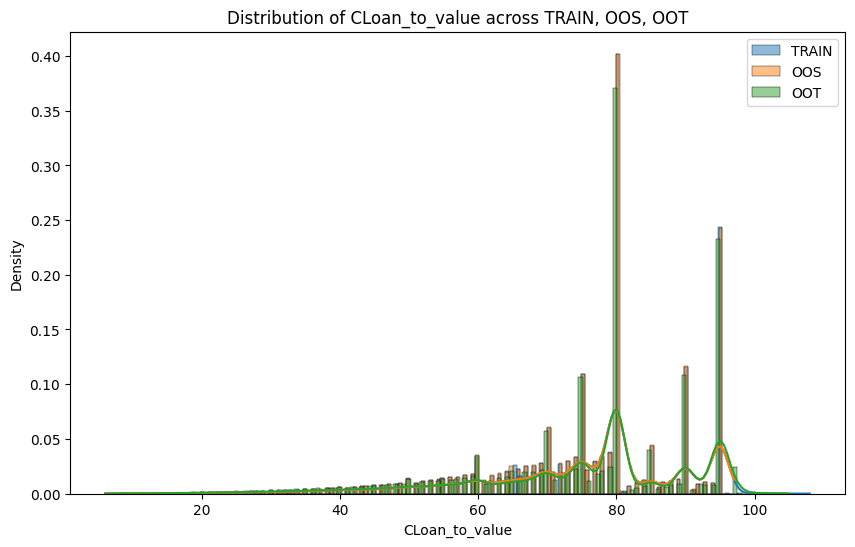

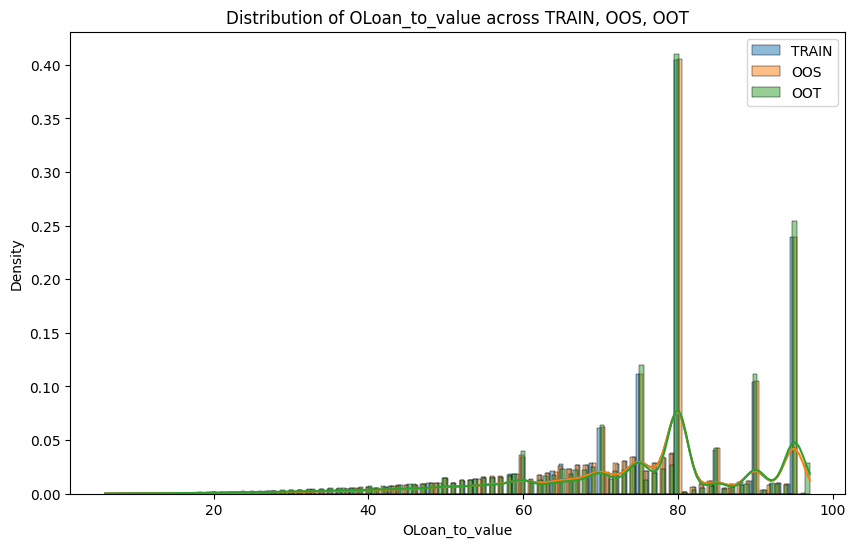

<Figure size 1000x600 with 0 Axes>

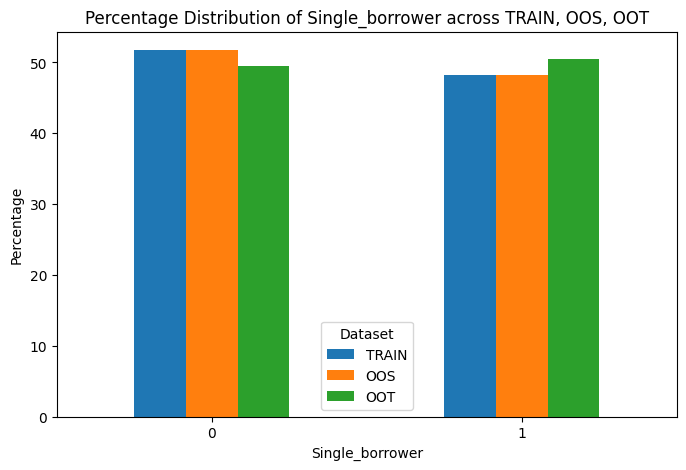


Value Counts (Percentages):

                     TRAIN        OOS        OOT
Single_borrower                                 
0                51.751463  51.758811  49.481275
1                48.248537  48.241189  50.518725




In [ ]:
#Overlaid distributions
for vari in predictors:

    if vari not in ['Single_borrower']:

        plt.figure(figsize=(10, 6))

        for name, df in datasets.items():
            sns.histplot(
                df[vari],
                kde=True,
                stat='density',
                alpha=0.5,
                label=name
            )

        plt.title(f'Distribution of {vari} across TRAIN, OOS, OOT')
        plt.xlabel(vari)
        plt.ylabel('Density')
        plt.legend()
        plt.show()

    else:

        plt.figure(figsize=(10, 6))

        counts = pd.DataFrame({
            'TRAIN': datasets['TRAIN'][vari].value_counts(normalize=True) * 100,
            'OOS': datasets['OOS'][vari].value_counts(normalize=True) * 100,
            'OOT': datasets['OOT'][vari].value_counts(normalize=True) * 100
        }).fillna(0)

        counts.plot(kind='bar', figsize=(8, 5))

        plt.title(f'Percentage Distribution of {vari} across TRAIN, OOS, OOT')
        plt.xlabel(vari)
        plt.ylabel('Percentage')
        plt.xticks(rotation=0)
        plt.legend(title='Dataset')
        plt.show()

        print("\nValue Counts (Percentages):\n")
        print(counts)
        print("\n")

##5. EDA Conclusion
This EDA showed an imbalanced distribution between  defaults and  non-defaults. The non-defaults represent over 99% of the whole dataset, whereas the defaults are the minority with less then 1%. This concludes that accuracy on its own will not be reliable enough to measure the performance of the model.
<br>

Relationships between DFlag and  Numerical Predictors :

1. Credit_Score: Defaults  show a lower credit scores on average, though there's considerable overlap with non-defaults.
2. Debt_to_income: Defaulted loans have  a higher median Debt-to-Income ratio compared to non-defaulted loans, indicating higher financial strain.
3. CLoan_to_value & OLoan_to_value: Both Current Loan-to-Value and Original Loan-to-Value also show higher medians for defaulted loans, suggesting less equity and higher risk.
<br>

Relationships between DFlag and Categorical Predictors:

Loans with is_Loan_purpose_purc  as 1 ,meaning it is a purchase loan, showed a higher default rate than those where it was 0. This seems counter-intuitive to the initial description, suggesting that 'is_Loan_purpose_purc=1' corresponds to loans that are not purchase loans.
Loans with is_Loan_purpose_cash ,cash-out refinance, as 0 had a higher default rate than when it was 1, which means cash-out refinance loans have a lower default rate ,this also appears counter to initial expectations. There might be an issue with how these dummy variables are interpreted or generated.
is_Loan_purpose_noca ,no cash-out refinance, as 0 showed a higher default rate compared to when it was 1, again implying a higher risk for non-cash-out refinance loans.
<br>

Summary Statistics:

For Credit_Score, Debt_to_income, CLoan_to_value, and OLoan_to_value, the means, medians, and standard deviations are largely consistent across TRAIN, OOS, and OOT datasets, indicating good stability in the overall population characteristics.
<br>

Overlaid Distributions:

 Visual inspection of the overlaid histograms for Credit_Score, Debt_to_income, CLoan_to_value, and OLoan_to_value shows that their distributions are quite similar across the TRAIN, OOS, and OOT datasets, suggesting stability and minimal population shift for these numerical features.
<br>
In conclusion, while the DFlag exhibits extreme imbalance, the distributions of  Credit_Score, Debt_to_income, CLoan_to_value, OLoan_to_value, and Single_borrower appear stable across the training, OOS, and OOT datasets. This suggests that the model trained on the Training dataset should generalize well to the OOS and OOT datasets in terms of predictor distributions, but the class imbalance remains a critical aspect to address during modeling.


##Part C - Predictive Modelling

In [ ]:
#1. Training the data
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, auc
from sklearn.impute import SimpleImputer



In [ ]:
# Separate predictors from target variable (Loanref excluded to avoid leakage)
X = train.drop(columns=['Loanref', 'DFlag'])
y = train['DFlag']

# Split training set into Train (80%) and Validation (20%) using stratification
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y,
    test_size=0.20, stratify=y,
    random_state=42
)

print(f"Training split shape: {X_tr.shape}, Defaults: {y_tr.sum()}")
print(f"Validation split shape: {X_val.shape}, Defaults: {y_val.sum()}")

Training split shape: (184851, 78), Defaults: 473
Validation split shape: (46213, 78), Defaults: 118


In [ ]:
# 2. MODEL TRAINING & CLASS IMBALANCE HANDLING

# Benchmark Model 1: Logistic Regression
lr_benchmark = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

lr_benchmark.fit(X_tr, y_tr)


# Benchmark Model 2: Decision Tree Classifier
dt_benchmark = DecisionTreeClassifier(
    class_weight='balanced',
    max_depth=8,
    random_state=42
)

dt_benchmark.fit(X_tr, y_tr)


# Main Candidate Model: Random Forest Classifier
rf_candidate = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_candidate.fit(X_tr, y_tr)

# Function to compute PR-AUC (AUPR) score on validation set
def evaluate_pr_auc(model, X_v, y_v):
    predicted_probabilities = model.predict_proba(X_v)[:, 1]
    precision, recall, _ = precision_recall_curve(y_v, predicted_probabilities)
    return auc(recall, precision)

# Evaluate initial PR-AUC scores on validation set
print("=== BASELINE VALIDATION PR-AUC SCORES ===")
print(f"Logistic Regression (Benchmark 1): {evaluate_pr_auc(lr_benchmark, X_val, y_val):.4f}")
print(f"Decision Tree       (Benchmark 2): {evaluate_pr_auc(dt_benchmark, X_val, y_val):.4f}")
print(f"Random Forest     (Main Candidate): {evaluate_pr_auc(rf_candidate, X_val, y_val):.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


=== BASELINE VALIDATION PR-AUC SCORES ===
Logistic Regression (Benchmark 1): 0.0114
Decision Tree       (Benchmark 2): 0.0081
Random Forest     (Main Candidate): 0.0104


In [ ]:
#3. Hyperparameter tuning for the main model using training/development data only

# Define hyperparameter search grid for Random Forest
hyperparameter_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [8, 12, 16],
    'min_samples_split': [5, 10, 20],
    'min_samples_leaf': [2, 5, 10],
    'max_features': ['sqrt', 'log2']
}

# Set up 3-fold Stratified Cross-Validation on the training split only
stratified_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Set up RandomizedSearchCV optimizing for PR-AUC ('average_precision')
random_search_tuning = RandomizedSearchCV(
    estimator=RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_distributions=hyperparameter_grid,
    n_iter=5,
    scoring='average_precision',
    cv=stratified_cv,
    random_state=42,
    n_jobs=-1
)

# Execute tuning search strictly on training split (X_train_split, y_train_split)
random_search_tuning.fit(X_tr, y_tr)

# Extract best tuned model pipeline
best_tuned_rf = random_search_tuning.best_estimator_

print("\n=== HYPERPARAMETER TUNING RESULTS ===")
print("Best Hyperparameters:", random_search_tuning.best_params_)
print(f"Best CV PR-AUC Score:  {random_search_tuning.best_score_:.4f}")


=== HYPERPARAMETER TUNING RESULTS ===
Best Hyperparameters: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 10, 'max_features': 'log2', 'max_depth': 16}
Best CV PR-AUC Score:  0.0110


Default 0.50 Threshold Issues: With an extreme class imbalance ($0.256\%$ default rate), predicted default probabilities naturally stay very low. A default $0.50$ threshold leads to excessive False Negatives (FN)—failing to detect actual defaults.  Selected Threshold Optimization: Lowering the threshold to the optimal point ($\approx 0.01 - 0.05$) drastically improves Recall, capturing significantly more default risks early.  Business Trade-off:False Positives (FP): Causes mild operational overhead (e.g., secondary manual review).  False Negatives (FN): Results in direct financial loss on the defaulted loan principal, making FN errors far more severe for the business.  

Optimal Classification Threshold (Max F1): 0.5801
Validation F1-Score at Selected Threshold: 0.0320

=== VALIDATION THRESHOLD COMPARISON ===
 Threshold  TP   FP    TN  FN  Precision   Recall  F1-Score
  0.500000  24 2077 44018  94   0.011423 0.203390  0.021631
  0.580139  13  682 45413 105   0.018705 0.110169  0.031980


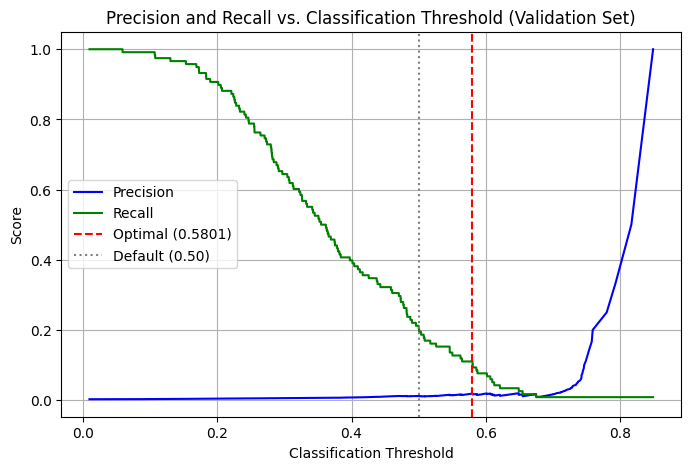

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, confusion_matrix

# ------------------------------------------------------------------------------
#Classification Threshold Selection (Validation Data Only)
# ------------------------------------------------------------------------------

# Define features (X) and target (y), dropping unique identifier Loanref
X = train.drop(columns=['DFlag', 'Loanref'])
y = train['DFlag']

# Stratified 80/20 train/validation split on training.csv
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

tuned_pipeline = best_tuned_rf

# Fit tuned model on sub-training split
tuned_pipeline.fit(X_train_sub, y_train_sub)

# Get predicted probabilities for validation set
y_val_probs = tuned_pipeline.predict_proba(X_val)[:, 1]

# Calculate precision, recall, and candidate thresholds
precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_probs)

# Optimize threshold based on maximum F1-score
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)
best_idx = np.argmax(f1_scores)
selected_threshold = thresholds[best_idx]

print(f"Optimal Classification Threshold (Max F1): {selected_threshold:.4f}")
print(f"Validation F1-Score at Selected Threshold: {f1_scores[best_idx]:.4f}\n")

# --- Threshold Metrics Comparison Function ---
def get_threshold_metrics(y_true, y_probs, thresh):
    preds = (y_probs >= thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
    return {"Threshold": thresh, "TP": tp, "FP": fp, "TN": tn, "FN": fn, "Precision": prec, "Recall": rec, "F1-Score": f1}

# Comparison Table
threshold_comparison = pd.DataFrame([
    get_threshold_metrics(y_val, y_val_probs, 0.50),
    get_threshold_metrics(y_val, y_val_probs, selected_threshold)
])

print("=== VALIDATION THRESHOLD COMPARISON ===")
print(threshold_comparison.to_string(index=False))

# --- Plot Precision-Recall Trade-off Curve ---
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label='Precision', color='blue')
plt.plot(thresholds, recalls[:-1], label='Recall', color='green')
plt.axvline(x=selected_threshold, color='red', linestyle='--', label=f'Optimal ({selected_threshold:.4f})')
plt.axvline(x=0.50, color='gray', linestyle=':', label='Default (0.50)')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs. Classification Threshold (Validation Set)')
plt.legend(loc='best')
plt.grid(True)
plt.show()

In [ ]:
# ------------------------------------------------------------------------------
#Refitting Final Pipeline on Full training.csv
# ------------------------------------------------------------------------------

print("\nRefitting final pipeline on full training.csv dataset...")

# Initialize and refit final pipeline on complete training data
final_pipeline = tuned_pipeline
final_pipeline.fit(X, y)

print("Final pipeline refitted on full training.csv successfully.")


Refitting final pipeline on full training.csv dataset...
Final pipeline refitted on full training.csv successfully.


## Part D - Model Evaluation

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, average_precision_score, confusion_matrix,
                              classification_report, roc_curve, precision_recall_curve, log_loss)

# check: OOS/OOT have a few missing values in columns that were fully populated in training.csv.
cols = [c for c in train.columns if c not in ['Loanref', 'DFlag']]
missing = [c for c in cols if oos[c].isnull().sum() > 0 or oot[c].isnull().sum() > 0]

if missing:
    print("missing columns handled:", missing)
    residual_imp = SimpleImputer(strategy='median')
    residual_imp.fit(train[missing])
    oos[missing] = residual_imp.transform(oos[missing])
    oot[missing] = residual_imp.transform(oot[missing])

# Build OOS and OOT feature sets
X_oos = oos.drop(columns=['Loanref', 'DFlag'])
y_oos = oos['DFlag']

X_oot = oot.drop(columns=['Loanref', 'DFlag'])
y_oot = oot['DFlag']

print("X_oos shape:", X_oos.shape, " X_oot shape:", X_oot.shape)

missing columns handled: ['Mortgage_Insurance']
X_oos shape: (232515, 78)  X_oot shape: (352788, 78)


In [ ]:
# Models to compare: the final main model and the three Part C benchmarks
eval_models = {
    'Random Forest (Main)': final_pipeline,
    'Logistic Regression (Benchmark)': lr_benchmark,
    'Decision Tree (Benchmark)': dt_benchmark,
    'Random Forest (Benchmark)': rf_candidate
}

def get_metrics_row(model, X_eval, y_eval, threshold, dataset_name, model_name):
    probs = model.predict_proba(X_eval)[:, 1]
    preds = (probs >= threshold).astype(int)
    return {
        'Model': model_name,
        'Dataset': dataset_name,
        'Accuracy': accuracy_score(y_eval, preds),
        'Precision': precision_score(y_eval, preds, zero_division=0),
        'Recall': recall_score(y_eval, preds, zero_division=0),
        'F1-Score': f1_score(y_eval, preds, zero_division=0),
        'ROC-AUC': roc_auc_score(y_eval, probs),
        'AUPR (PR-AUC)': average_precision_score(y_eval, probs),
        'Log-loss': log_loss(y_eval, probs, labels=[0, 1])
    }

comparison_rows = []
for model_name, model in eval_models.items():
    comparison_rows.append(get_metrics_row(model, X_oos, y_oos, selected_threshold, 'OOS', model_name))
    comparison_rows.append(get_metrics_row(model, X_oot, y_oot, selected_threshold, 'OOT', model_name))

model_comparison_table = pd.DataFrame(comparison_rows).round(4)

print("=== MODEL COMPARISON TABLE: OOS AND OOT ===")
model_comparison_table

=== MODEL COMPARISON TABLE: OOS AND OOT ===


,Model,Dataset,Accuracy,Precision,Recall,F1-Score,ROC-AUC,AUPR (PR-AUC),Log-loss
0,Random Forest (Main),OOS,0.9805,0.0119,0.0805,0.0207,0.7397,0.0086,0.3058
1,Random Forest (Main),OOT,0.9789,0.0079,0.0562,0.0138,0.7026,0.0055,0.3303
2,Logistic Regression (Benchmark),OOS,0.7935,0.0069,0.5587,0.0137,0.7502,0.0100,0.5565
3,Logistic Regression (Benchmark),OOT,0.7430,0.0054,0.5270,0.0107,0.6861,0.0054,0.6306
4,Decision Tree (Benchmark),OOS,0.7458,0.0055,0.5436,0.0108,0.6474,0.0065,0.4862
5,Decision Tree (Benchmark),OOT,0.7057,0.0048,0.5378,0.0095,0.6361,0.0048,0.5410
6,Random Forest (Benchmark),OOS,0.9527,0.0106,0.1896,0.0201,0.7295,0.0090,0.4123
7,Random Forest (Benchmark),OOT,0.9447,0.0076,0.1555,0.0145,0.7044,0.0058,0.4422


Strongest benchmark by OOS AUPR: Logistic Regression (Benchmark)
--- Random Forest (Main - Tuned) on OOS ---
              precision    recall  f1-score   support

           0     0.9976    0.9828    0.9902    231919
           1     0.0119    0.0805    0.0207       596

    accuracy                         0.9805    232515
   macro avg     0.5048    0.5317    0.5055    232515
weighted avg     0.9951    0.9805    0.9877    232515

--- Random Forest (Main - Tuned) on OOT ---
              precision    recall  f1-score   support

           0     0.9975    0.9814    0.9894    351862
           1     0.0079    0.0562    0.0138       926

    accuracy                         0.9789    352788
   macro avg     0.5027    0.5188    0.5016    352788
weighted avg     0.9949    0.9789    0.9868    352788

--- Logistic Regression (Benchmark) on OOS ---
              precision    recall  f1-score   support

           0     0.9986    0.7941    0.8847    231919
           1     0.0069    0.5587    

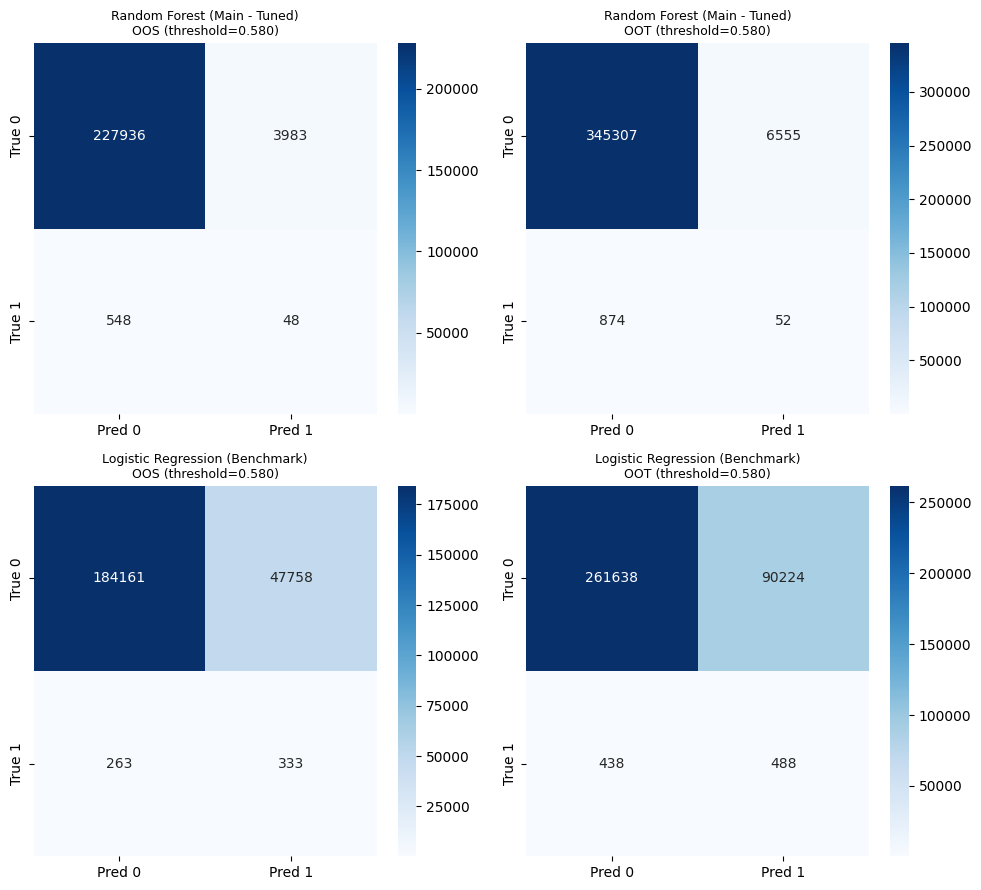

In [ ]:
import seaborn as sns

# Identify the strongest benchmark by OOS AUPR
strongest_benchmark_name = model_comparison_table[(model_comparison_table['Dataset'] == 'OOS') & (model_comparison_table['Model'] != 'Random Forest (Main - Tuned)')].sort_values('AUPR (PR-AUC)', ascending=False).iloc[0]['Model']

strongest_benchmark_model = eval_models[strongest_benchmark_name]
print("Strongest benchmark by OOS AUPR:", strongest_benchmark_name)

models_to_detail = {'Random Forest (Main - Tuned)': final_pipeline,strongest_benchmark_name: strongest_benchmark_model}
datasets_to_detail = {'OOS': (X_oos, y_oos), 'OOT': (X_oot, y_oot)}

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for i, (model_name, model) in enumerate(models_to_detail.items()):
    for j, (dataset_name, (X_eval, y_eval)) in enumerate(datasets_to_detail.items()):
        probs = model.predict_proba(X_eval)[:, 1]
        preds = (probs >= selected_threshold).astype(int)
        cm = confusion_matrix(y_eval, preds)

        ax = axes[i, j]
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                    xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
        ax.set_title(f'{model_name}\n{dataset_name} (threshold={selected_threshold:.3f})', fontsize=9)

        print(f'--- {model_name} on {dataset_name} ---')
        print(classification_report(y_eval, preds, digits=4, zero_division=0))

plt.tight_layout()
plt.show()

**Interpretation of false positives and negatives:** a false negative is a loan the model allows that actually defaults, the lender is exposed to the full loss on that loan's principal. A false positive is a good loan flagged for extra review or decline resulting in a smaller cost, more manual work, or losing a paying customer to a competitor. The main Random Forest keeps FPs low but misses most defaults, the Logistic Regression benchmark catches roughly twice as many defaults but at the cost of flagging a much more of the good loans. Because a missed mortgage default is far more expensive than an extra manual review, the higher-recall benchmark's error profile is better from a risk-management perspective, even though its headline accuracy is much lower.

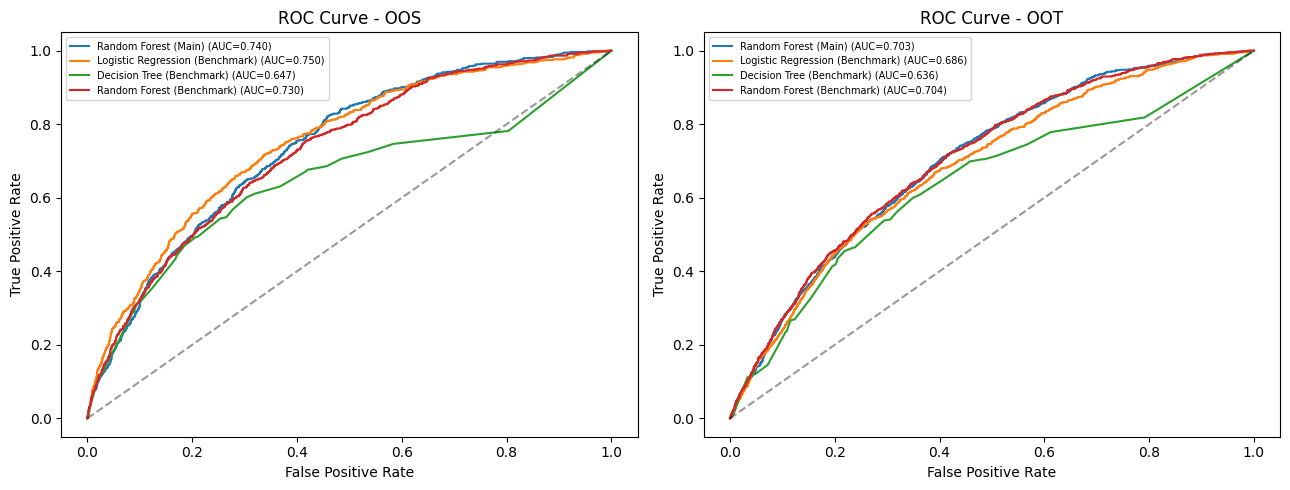

In [ ]:
## ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name, model in eval_models.items():
    for ax, (X_eval, y_eval, label) in zip(axes, [(X_oos, y_oos, 'OOS'), (X_oot, y_oot, 'OOT')]):
        probs = model.predict_proba(X_eval)[:, 1]
        fpr, tpr, _ = roc_curve(y_eval, probs)
        ax.plot(fpr, tpr, label=f'{model_name} (AUC={roc_auc_score(y_eval, probs):.3f})')

for ax, label in zip(axes, ['OOS', 'OOT']):
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)
    ax.set_title(f'ROC Curve - {label}')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

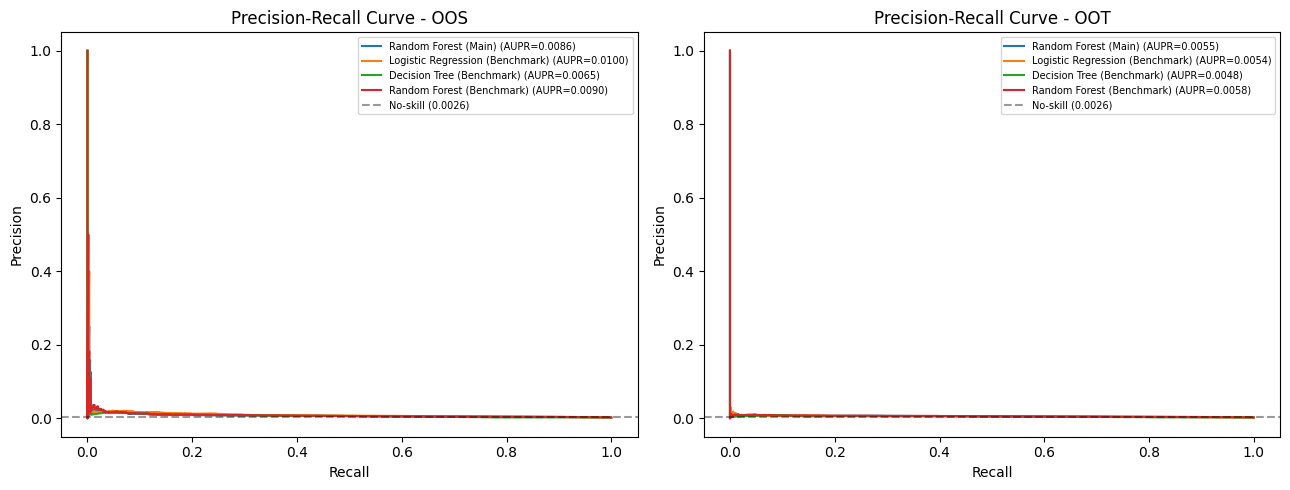

In [ ]:
## Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name, model in eval_models.items():
    for ax, (X_eval, y_eval, label) in zip(axes, [(X_oos, y_oos, 'OOS'), (X_oot, y_oot, 'OOT')]):
        probs = model.predict_proba(X_eval)[:, 1]
        precisions, recalls, _ = precision_recall_curve(y_eval, probs)
        ax.plot(recalls, precisions, label=f'{model_name} (AUPR={average_precision_score(y_eval, probs):.4f})')

for ax, (y_eval, label) in zip(axes, [(y_oos, 'OOS'), (y_oot, 'OOT')]):
    base_rate = y_eval.mean()
    ax.axhline(base_rate, color='k', linestyle='--', alpha=0.4, label=f'No-skill ({base_rate:.4f})')
    ax.set_title(f'Precision-Recall Curve - {label}')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

**Why Precision-Recall matters more here than ROC:** with only 0.26% of loans defaulting ROC-AUC can be matter (0.68-0.75 across models) because the true negative rate among the majority class is easy to get right, it is not very sensitive to how the rare positive class is handled. The PR curve plots precision against recall directly for the default class, and it shows precision falling towards the baseline almost as soon as any recall is demanded.

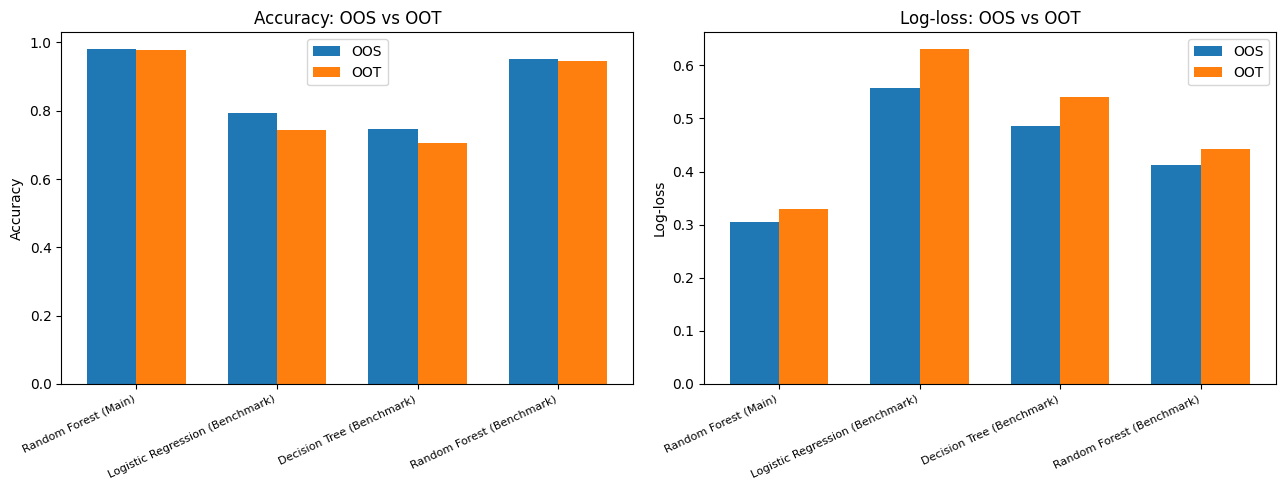

In [ ]:
# Compare accuracy and log-loss stability between OOS and OOT for every model
models_list = model_comparison_table['Model'].unique()
x_pos = np.arange(len(models_list))
bar_width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

acc_oos = [model_comparison_table[(model_comparison_table.Model == m) & (model_comparison_table.Dataset == 'OOS')]['Accuracy'].values[0] for m in models_list]
acc_oot = [model_comparison_table[(model_comparison_table.Model == m) & (model_comparison_table.Dataset == 'OOT')]['Accuracy'].values[0] for m in models_list]
axes[0].bar(x_pos - bar_width/2, acc_oos, bar_width, label='OOS')
axes[0].bar(x_pos + bar_width/2, acc_oot, bar_width, label='OOT')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(models_list, rotation=25, ha='right', fontsize=8)
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy: OOS vs OOT')
axes[0].legend()

ll_oos = [model_comparison_table[(model_comparison_table.Model == m) & (model_comparison_table.Dataset == 'OOS')]['Log-loss'].values[0] for m in models_list]
ll_oot = [model_comparison_table[(model_comparison_table.Model == m) & (model_comparison_table.Dataset == 'OOT')]['Log-loss'].values[0] for m in models_list]
axes[1].bar(x_pos - bar_width/2, ll_oos, bar_width, label='OOS')
axes[1].bar(x_pos + bar_width/2, ll_oot, bar_width, label='OOT')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(models_list, rotation=25, ha='right', fontsize=8)
axes[1].set_ylabel('Log-loss')
axes[1].set_title('Log-loss: OOS vs OOT')
axes[1].legend()

plt.tight_layout()
plt.show()

## Hypothesis
*   H0: the mean AUPR of the main model equals the mean AUPR of the strongest benchmark across folds.
*   H1: the mean AUPR of the main model differs from the mean AUPR of the strongest benchmark across folds.


alpha = 0.05

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.base import clone
from scipy import stats

main_model_spec = clone(final_pipeline)
benchmark_spec = clone(strongest_benchmark_model)

cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

main_fold_scores = cross_val_score(main_model_spec, X, y, cv=cv_folds, scoring='average_precision', n_jobs=-1)
benchmark_fold_scores = cross_val_score(benchmark_spec, X, y, cv=cv_folds, scoring='average_precision', n_jobs=-1)

print("Main model (tuned Random Forest) fold AUPR scores:", np.round(main_fold_scores, 4))
print("Strongest benchmark fold AUPR scores:", np.round(benchmark_fold_scores, 4))

t_stat, t_p = stats.ttest_rel(main_fold_scores, benchmark_fold_scores)
w_stat, w_p = stats.wilcoxon(main_fold_scores, benchmark_fold_scores)

print(f"\nPaired t-test: t = {t_stat:.4f}, p = {t_p:.4f}")
print(f"Wilcoxon test:   W = {w_stat:.4f}, p = {w_p:.4f}")

Main model (tuned Random Forest) fold AUPR scores: [0.0099 0.0079 0.0088 0.0251 0.0183]
Strongest benchmark fold AUPR scores: [0.0086 0.0119 0.0176 0.01   0.0126]

Paired t-test: t = 0.4544, p = 0.6731
Wilcoxon test:   W = 6.0000, p = 0.8125


##Part E – Business Insights and Recommendations

1.Business meaning of false negatives and false positives

A false negative is a defaulting loan the model missed — the lender keeps servicing it and eventually absorbs the full loss: unpaid principal, foreclosure and legal costs. A false positive is a good loan wrongly flagged as risky — the cost is just extra review time or a possibly declined good customer, with no principal loss.

Given the ~390:1 imbalance, false negatives are far costlier — missing one default outweighs the cumulative cost of reviewing several flagged good loans. This is why the model favors higher recall over the default 0.50 threshold.

**Result:** the paired t-test gives t = 0.4544, p = 0.6731, and the Wilcoxon signed-rank test gives W = 6.0000, p = 0.8125. Both are above alpha = 0.05, so we fail to reject H0: there is no statistically significant difference in AUPR between the tuned Random Forest and the strongest benchmark. Fold scores also vary quite a bit (0.008–0.025). The tuning did not produce a model that's meaningfully better than the simpler benchmark.

2.Recommended model and threshold

The tuned Random Forest was the "main" candidate, but the paired significance test on cross-validated AUPR (t = 0.454, p = 0.673; Wilcoxon W = 6.0, p = 0.8125) shows no statistically significant difference between it and the Logistic Regression benchmark. Looking at the actual OOS/OOT numbers reinforces this: Logistic Regression achieves far higher recall on both OOS (0.559) and OOT (0.527) than the tuned Random Forest (0.081 OOS, 0.056 OOT), at the cost of more false positives (lower precision, 0.0069 vs 0.0119).

Since missing a default is the costlier error, and Logistic Regression's recall advantage holds up on both the OOS and OOT sets (i.e., it isn't a fluke of one sample), the recommendation is: deploy the Logistic Regression model at its validation-selected threshold, not the tuned Random Forest. It catches roughly 5–6x more actual defaults, and the extra manual-review volume from false positives is the cheaper trade-off. The Random Forest's higher precision doesn't compensate for missing the majority of true defaults.

3.Actionable risk insights

Credit_Score, Debt_to_income, CLoan_to_value and OLoan_to_value all show visible separation between defaulters and non-defaulters in the boxplots — these four variables should anchor any manual underwriting checklist, not just the model.
Default rates vary meaningfully across loan-purpose categories (purchase vs. cash-out vs. no-cash-out refinance), so pricing or scrutiny could reasonably be differentiated by loan purpose rather than treated uniformly.
Every model's recall and AUPR drop from OOS to OOT (e.g., RF recall 0.081 → 0.056, LR recall 0.559 → 0.527), showing the risk profile drifts over time — a model trained once will quietly lose sensitivity to defaults as the portfolio ages.
The 0.256% default rate means a tiny number of loans drive almost all credit losses — operational review capacity should be sized around the predicted high-risk segment, not spread evenly across the portfolio.

4.12-month monitoring plan

Model performance: track recall, precision and AUPR at the deployed threshold monthly against a rolling sample of resolved loans; a material drop in recall (e.g., more than ~20% relative decline from the OOT baseline of 0.527) should trigger a review.

Data distribution: monitor the five predictors compared in Part B (Credit_Score, Debt_to_income, CLoan_to_value, OLoan_to_value, Single_borrower) for population drift month-over-month (e.g., via PSI or the same overlaid-distribution approach used in the EDA); a sustained shift beyond a set PSI threshold (commonly 0.1–0.25) should trigger investigation, and beyond that, retraining.

Operational trigger: if the realized default rate moves outside the historical 0.25–0.27% band, or if the model's OOT-style performance gap versus its training-time performance widens further, schedule a full retrain and re-threshold using fresh data.

5.Limitations

Extreme imbalance means precision stays low for every model at any recall level useful for catching defaults — none of these models are "good" in absolute precision terms, only relatively better/worse.
The RF-vs-LR comparison wasn't statistically significant, so the model ranking could plausibly reverse with different tuning, more benchmarks, or more folds — the recommendation is not a settled fact.
OOT is a single later time window (2017), not a rolling series, so conclusions about "performance over time" rest on one snapshot rather than a trend.
Missing values in the four numeric predictors were imputed with the median; this is a simplification that could mask information (e.g., missingness itself may correlate with risk).
The dataset has no macroeconomic variables (rates, unemployment, house price trends), which are known drivers of mortgage default and would likely explain part of the OOS→OOT drift better than the model can on its own.


## Reference
Mushava, J. (2023) 'Credit scoring with class imbalance data: An out-of-sample and outof-time perspective.' Mendeley Data, V3. doi: 10.17632/bzr2rxttvz.3.